# Flowers 102 por dentro: el artículo original de Nilsback y Zisserman

Todo el módulo 3 usa Oxford Flowers 102: las 8.189 fotos de flores con las que el jardín botánico quiere armar su app. Pero el dataset no nació para enseñar a cargar datos. Lo publicaron en 2008 Maria-Elena Nilsback y Andrew Zisserman, del Visual Geometry Group (VGG) de Oxford, en el artículo [*Automated flower classification over a large number of classes*](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/), que el curso recomienda junto con la [página del dataset](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/).

El artículo es de antes de que las redes convolucionales dominaran la visión por computador. Para clasificar flores, los autores **diseñan a mano** qué mirar en cada foto (el color, la forma de los pétalos, su disposición) y después combinan esas medidas con un clasificador. Este notebook lee el artículo y reproduce sus ideas centrales en código:

- comprueba con los archivos lo que el artículo y la página dicen del dataset, incluidas dos diferencias entre ellos;
- usa la **división oficial** (10 fotos por clase para entrenar) y la métrica del artículo, la exactitud **promediada por clase**;
- separa la flor del fondo con las **segmentaciones** que publicaron los autores;
- construye tres de sus descriptores en versión simplificada: **palabras de color** en HSV, **palabras de gradientes locales** (una versión pobre de SIFT) y **HOG**;
- los convierte en **kernels** y los combina, que es la tesis del artículo: la combinación supera por mucho a la mejor característica sola;
- pone a prueba los ejemplos del artículo: qué flores se distinguen por el color y cuáles por la forma;
- y mira qué cambió desde 2008.

El notebook tarda unos cuatro minutos en una CPU. La mayor parte se va en leer las 8.189 fotos y sus segmentaciones, y en comparar los histogramas de todas contra todas.

**Contenido**

1. Preparación
2. El artículo en pocas palabras
3. Lo que dice del dataset, comprobado
4. La división oficial y cómo se mide
5. La segmentación: separar la flor del fondo
6. Leer las 8.189 fotos una vez
7. Color: palabras visuales en HSV
8. Forma: gradientes locales y HOG
9. Un primer clasificador: el vecino más cercano
10. Kernels: de distancias a similitudes
11. Combinar características
12. ¿Ayuda segmentar?
13. Qué característica sirve para qué flor
14. Clase por clase
15. Qué cambió desde 2008
16. Resumen y ejercicios

## 1. Preparación

Usamos los archivos crudos del dataset, como en `00-acceso/01_un_dataset_propio`: las fotos en `jpg/`, las etiquetas en `imagelabels.mat` y la división oficial en `setid.mat`. `datasets.Flowers102` solo se usa para descargarlos si faltan. Las etiquetas van de 1 a 102 y los números de foto de 1 a 8.189, así que a los dos les restamos 1 para trabajar con índices desde 0.

In [1]:
import time

import numpy as np
import scipy.io
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import datasets
from torchvision.datasets.utils import download_and_extract_archive
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"                          # modulo-3/data
CARPETA = f"{RAIZ}/flowers-102"
datasets.Flowers102(root=RAIZ, split="test", download=True)     # descarga fotos, etiquetas y división si faltan

etiquetas = torch.tensor(scipy.io.loadmat(f"{CARPETA}/imagelabels.mat")["labels"][0].astype(np.int64)) - 1
division = scipy.io.loadmat(f"{CARPETA}/setid.mat")
entrenamiento, validacion, prueba = [torch.tensor(division[k][0].astype(np.int64)) - 1
                                     for k in ["trnid", "valid", "tstid"]]
N = len(etiquetas)
print("fotos:", N, "  clases:", len(etiquetas.unique()))

Versión de PyTorch: 2.11.0+cpu
fotos: 8189   clases: 102


Los nombres de las clases no vienen en los archivos. Esta es la lista en el orden de las etiquetas, la misma que usan torchvision y la copia del dataset en Hugging Face que conserva la división oficial ([`dpdl-benchmark/oxford_flowers102`](https://huggingface.co/datasets/dpdl-benchmark/oxford_flowers102)):

In [2]:
NOMBRES = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'english marigold',
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle', 'snapdragon',
    "colt's foot", 'king protea', 'spear thistle', 'yellow iris', 'globe-flower', 'purple coneflower',
    'peruvian lily', 'balloon flower', 'giant white arum lily', 'fire lily', 'pincushion flower',
    'fritillary', 'red ginger', 'grape hyacinth', 'corn poppy', 'prince of wales feathers',
    'stemless gentian', 'artichoke', 'sweet william', 'carnation', 'garden phlox', 'love in the mist',
    'mexican aster', 'alpine sea holly', 'ruby-lipped cattleya', 'cape flower', 'great masterwort',
    'siam tulip', 'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia',
    'bolero deep blue', 'wallflower', 'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia',
    'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium',
    'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata', 'japanese anemone', 'black-eyed susan',
    'silverbush', 'californian poppy', 'osteospermum', 'spring crocus', 'bearded iris', 'windflower',
    'tree poppy', 'gazania', 'azalea', 'water lily', 'rose', 'thorn apple', 'morning glory',
    'passion flower', 'lotus', 'toad lily', 'anthurium', 'frangipani', 'clematis', 'hibiscus', 'columbine',
    'desert-rose', 'tree mallow', 'magnolia', 'cyclamen', 'watercress', 'canna lily', 'hippeastrum',
    'bee balm', 'ball moss', 'foxglove', 'bougainvillea', 'camellia', 'mallow', 'mexican petunia',
    'bromelia', 'blanket flower', 'trumpet creeper', 'blackberry lily'
]
print(len(NOMBRES), "nombres")

102 nombres


Una lista de nombres copiada de otro lado es justo el tipo de cosa que conviene comprobar antes de confiar en ella. La [página de categorías del VGG](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/categories.html) muestra, para cada clase, una miniatura de una de sus fotos y cuántas fotos tiene. La miniatura `thumbim_06974.jpg` es la foto `image_06974.jpg`, así que podemos buscar su etiqueta en el `.mat` y ver si el nombre y el conteo calzan. Lo hacemos con once clases, las que usa este notebook:

In [3]:
# miniatura de la página de categorías -> (nombre y número de fotos que dice la página)
PAGINA = {6974: ("alpine sea holly", 43), 1456: ("petunia", 258), 5: ("passion flower", 251),
          6757: ("pink primrose", 40), 5414: ("sunflower", 61), 6224: ("oxeye daisy", 49),
          4657: ("buttercup", 71), 6317: ("common dandelion", 92), 3117: ("snapdragon", 87),
          5061: ("orange dahlia", 67), 6249: ("cautleya spicata", 50)}

conteos = torch.bincount(etiquetas, minlength=102)
for foto, (nombre_pagina, n_pagina) in PAGINA.items():
    clase = etiquetas[foto - 1].item()
    calza = NOMBRES[clase] == nombre_pagina and conteos[clase].item() == n_pagina
    print(f"image_{foto:05d}: etiqueta {clase:3d} = {NOMBRES[clase]:17s} {conteos[clase].item():3d} fotos   "
          f"página: {nombre_pagina:17s} {n_pagina:3d}   {'calza' if calza else 'NO CALZA'}")

image_06974: etiqueta  34 = alpine sea holly   43 fotos   página: alpine sea holly   43   calza
image_01456: etiqueta  50 = petunia           258 fotos   página: petunia           258   calza
image_00005: etiqueta  76 = passion flower    251 fotos   página: passion flower    251   calza
image_06757: etiqueta   0 = pink primrose      40 fotos   página: pink primrose      40   calza
image_05414: etiqueta  53 = sunflower          61 fotos   página: sunflower          61   calza
image_06224: etiqueta  48 = oxeye daisy        49 fotos   página: oxeye daisy        49   calza
image_04657: etiqueta  47 = buttercup          71 fotos   página: buttercup          71   calza
image_06317: etiqueta  49 = common dandelion   92 fotos   página: common dandelion   92   calza
image_03117: etiqueta  10 = snapdragon         87 fotos   página: snapdragon         87   calza
image_05061: etiqueta  58 = orange dahlia      67 fotos   página: orange dahlia      67   calza
image_06249: etiqueta  60 = cautleya spi

Las once calzan: la etiqueta de la foto de muestra lleva al nombre correcto, y el número de fotos de esa etiqueta en el `.mat` es el que dice la página.

Unas funciones para mostrar fotos, que usaremos en todo el notebook. `Image.draft` le pide al decodificador JPEG una versión reducida de la foto; para JPEG, Pillow la obtiene decodificando directamente a una fracción del tamaño, que es más rápido que decodificar la foto completa y achicarla después ([documentación de `Image.draft`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.draft)).

In [4]:
def abrir(i, lado=200):
    """La foto i (desde 0), decodificada a un tamaño cercano a `lado`."""
    foto = Image.open(f"{CARPETA}/jpg/image_{i + 1:05d}.jpg")
    foto.draft("RGB", (lado, lado))
    return foto.convert("RGB")


def mostrar(indices, titulos=None, por_fila=6, alto=2.2):
    filas = (len(indices) + por_fila - 1) // por_fila
    fig, ejes = plt.subplots(filas, por_fila, figsize=(por_fila * alto, filas * alto), squeeze=False)
    for k, eje in enumerate(ejes.flat):
        eje.axis("off")
        if k < len(indices):
            eje.imshow(abrir(indices[k]))
            eje.set_title(titulos[k] if titulos else NOMBRES[etiquetas[indices[k]]], fontsize=9)
    plt.tight_layout()
    plt.show()


grande = Image.open(f"{CARPETA}/jpg/image_00001.jpg")
print("sin draft:", grande.size, "  con draft:", abrir(0).size)

sin draft: (591, 500)   con draft: (296, 250)


## 2. El artículo en pocas palabras

**El problema.** Clasificar muchas clases dentro de una sola categoría, las flores, es más difícil que separar bicicletas de gatos. El resumen del artículo lo dice con dos frases: hay una gran similitud *entre* clases y poca similitud *dentro* de cada clase ("large between class similarity and small within class similarity", [resumen](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/nilsback08.pdf)). Además, las flores no son rígidas: se doblan y deforman de muchas maneras, y eso agranda la variación dentro de cada clase (sección 1).

**Qué distingue a una flor de otra.** A veces el color, a veces la forma, a veces el dibujo de los pétalos. Los ejemplos del artículo: para separar un girasol de una margarita sirve el color y la forma casi no ayuda; para separar un ranúnculo (*buttercup*) de un diente de león (*dandelion*) sirve la forma y el color no (secciones 1 y 3). Los pondremos a prueba en la sección 13.

**El método**, en cuatro pasos:

1. **Segmentar** cada foto para quedarse con la flor y descartar el fondo (sección 2 del artículo).
2. Calcular cuatro **descriptores** sobre la flor: el color en HSV, SIFT dentro de la flor (textura y forma local), SIFT a lo largo del borde (forma del contorno) y HOG sobre la región de la flor (disposición general de los pétalos) (sección 3.1).
3. Convertir cada descriptor en un **histograma de palabras visuales**: se agrupan los valores con *k-means* y cada foto se describe por cuántas veces aparece cada grupo (sección 3.1).
4. Comparar histogramas con la distancia χ², convertir cada distancia en un **kernel** y combinar los cuatro kernels con pesos aprendidos para cada clase, en una máquina de vectores de soporte (SVM) uno contra el resto (sección 3.2).

**El resultado** (tabla 1): la mejor característica sola, SIFT dentro de la flor, logra 55.1%; la combinación de las cuatro, 72.8%.

Nosotros vamos a reproducir los pasos con piezas más simples. La meta no es igualar el 72.8%, sino ver con nuestros propios números si la idea central se sostiene.

## 3. Lo que dice del dataset, comprobado

La [página del VGG](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) describe el dataset así: 102 categorías de flores comunes en el Reino Unido, entre 40 y 258 fotos por clase, con grandes variaciones de escala, pose e iluminación. Contamos las fotos de cada clase:

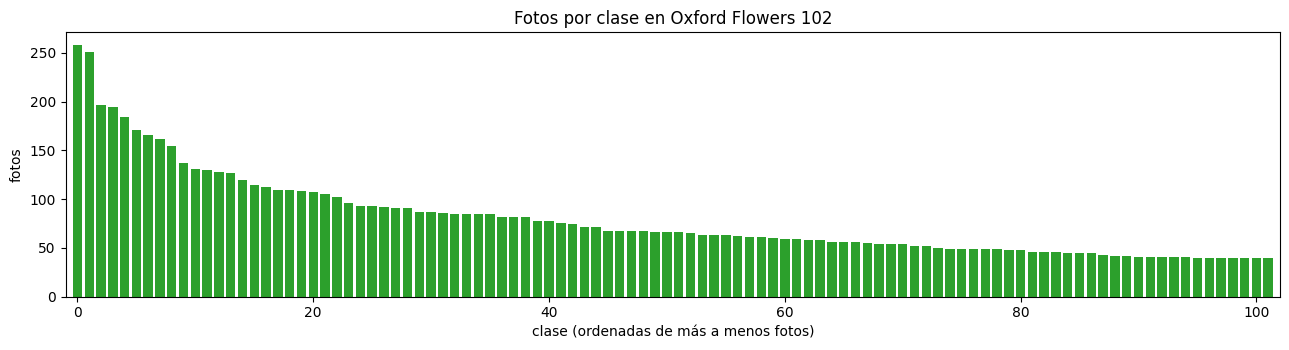

mínimo: 40   máximo: 258   mediana: 66
con más fotos : [('petunia', 258), ('passion flower', 251), ('wallflower', 196)]
con 40 fotos  : ['pink primrose', 'canterbury bells', 'moon orchid', 'fire lily', 'prince of wales feathers', 'mexican aster', 'bolero deep blue']


In [5]:
orden = conteos.argsort(descending=True)
fig, eje = plt.subplots(figsize=(13, 3.6))
eje.bar(range(102), conteos[orden], color="tab:green")
eje.set_xlabel("clase (ordenadas de más a menos fotos)")
eje.set_ylabel("fotos")
eje.set_title("Fotos por clase en Oxford Flowers 102")
eje.set_xlim(-1, 102)
plt.tight_layout()
plt.show()

print("mínimo:", conteos.min().item(), "  máximo:", conteos.max().item(), "  mediana:", conteos.median().item())
print("con más fotos :", [(NOMBRES[c], conteos[c].item()) for c in orden[:3].tolist()])
print("con 40 fotos  :", [NOMBRES[c] for c in torch.where(conteos == 40)[0].tolist()])

Entre 40 y 258, como dice la página, con una mediana de 66: la mitad de las clases tiene 66 fotos o menos. Pocas clases concentran muchas fotos.

El artículo dice otra cosa en dos detalles. Habla de **103** clases, de "between 40 and 250 images" por clase, y de que la flor de la pasión (*passion flower*) es la que tiene más (sección 4). Aquí la flor de la pasión tiene 251 y la que más tiene es la petunia, con 258. El [README del dataset](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/README.txt) explica la primera diferencia: los resultados del artículo se hicieron con 103 categorías, y después las dos categorías llamadas *Petunia* se fusionaron porque eran la misma flor. Al juntarlas, la petunia pasó a ser la clase más grande. Las 251 de la flor de la pasión contra las 250 del artículo quedan como una diferencia de una foto que el README no explica.

El artículo también dice que las fotos se reescalaron para que su lado más corto mida 500 píxeles (sección 4). Abrir una imagen con Pillow lee solo su encabezado, sin decodificarla, así que podemos medir las 8.189 en unos segundos:

In [6]:
inicio = time.perf_counter()
tamanos = torch.tensor([Image.open(f"{CARPETA}/jpg/image_{i + 1:05d}.jpg").size for i in range(N)])
print(f"leídos {N} encabezados en {time.perf_counter() - inicio:.1f} s")

lado_corto = tamanos.min(dim=1).values
valores, cuantas = lado_corto.unique(return_counts=True)
for v, c in zip(valores.tolist(), cuantas.tolist()):
    print(f"lado corto {v} px: {c} fotos")
print("lado largo: entre", tamanos.max(dim=1).values.min().item(), "y", tamanos.max(dim=1).values.max().item(), "px")

leídos 8189 encabezados en 6.9 s
lado corto 500 px: 7832 fotos
lado corto 501 px: 356 fotos
lado corto 707 px: 1 fotos
lado largo: entre 500 y 1168 px


Casi todas tienen el lado corto de 500 o 501 píxeles (el 501 es redondeo al reescalar), y una sola de 707. El lado largo varía mucho, porque las fotos tienen proporciones distintas: por eso en `01-calidad/01_transforms_para_fotos` hace falta `Resize` y `CenterCrop` antes de armar un lote.

Hay más copias del dataset dando vueltas, y no todas son iguales. En Hugging Face, [`dpdl-benchmark/oxford_flowers102`](https://huggingface.co/datasets/dpdl-benchmark/oxford_flowers102) conserva la división oficial (1.020, 1.020 y 6.149 fotos) y los nombres en el mismo orden que nuestra lista. Otra copia, [`nelorth/oxford-flowers`](https://huggingface.co/datasets/nelorth/oxford-flowers), tiene una división distinta (7.169 fotos de entrenamiento y 1.020 de prueba) y nombra las clases con números ordenados como texto: `'1'`, `'10'`, `'100'`, `'101'`, `'102'`, `'11'`… Ahí la etiqueta 2 corresponde a la clase 100 del archivo original. Es el mismo problema que aparece al ordenar carpetas por nombre, y la razón para revisar qué copia y qué división usa un resultado antes de compararlo con otro.

## 4. La división oficial y cómo se mide

`setid.mat` trae la división que usó el artículo. Contamos cuántas fotos de cada clase hay en cada parte:

In [7]:
for nombre, indices in [("entrenamiento", entrenamiento), ("validación", validacion), ("prueba", prueba)]:
    por_clase = torch.bincount(etiquetas[indices], minlength=102)
    print(f"{nombre:13s} {len(indices):5d} fotos   por clase: entre {por_clase.min().item()} y {por_clase.max().item()}")

todas = torch.cat([entrenamiento, validacion, prueba])
print("\n¿Cada foto está en exactamente una parte?", len(todas) == N and len(todas.unique()) == N)
petunia = NOMBRES.index("petunia")
print("petunia en prueba:", torch.bincount(etiquetas[prueba], minlength=102)[petunia].item(),
      "=", conteos[petunia].item(), "- 20")

entrenamiento  1020 fotos   por clase: entre 10 y 10
validación     1020 fotos   por clase: entre 10 y 10
prueba         6149 fotos   por clase: entre 20 y 238

¿Cada foto está en exactamente una parte? True
petunia en prueba: 238 = 258 - 20


Es exactamente lo que dice el artículo (sección 4): 10 fotos por clase para entrenar, 10 para validar, y el resto para la prueba, con un mínimo de 20 por clase. La prueba es enorme y muy desigual (de 20 a 238 fotos por clase), y el entrenamiento es diminuto: **10 fotos por clase**.

Los totales también cuadran con la fusión de las petunias. El artículo tenía 103 clases: 1.030 fotos de entrenamiento, 1.030 de validación y 6.129 de prueba. Hoy son 1.020, 1.020 y 6.149. Las 20 fotos que pierden entrenamiento y validación aparecen en la prueba (6.129 + 20 = 6.149), y la petunia tiene en la prueba todas sus fotos menos 20 (238 = 258 − 20). Es decir, la clase fusionada conservó 10 fotos de entrenamiento y 10 de validación, y las otras 20 de la segunda petunia pasaron a la prueba. Esto último lo deducimos de los números; el README solo dice que las clases se fusionaron.

**Cómo se mide.** El artículo mide la exactitud **por clase** y promedia sobre las clases, no sobre las fotos (sección 4). Con una prueba tan desigual, las dos cifras pueden ser muy distintas. El caso extremo es un modelo que contesta siempre lo mismo:

In [8]:
def exactitud_por_clase(prediccion, indices):
    """Fracción de aciertos de cada clase, entre las fotos de `indices`."""
    y = etiquetas[indices]
    aciertos = (prediccion == y).float()
    return torch.zeros(102).index_add_(0, y, aciertos) / torch.bincount(y, minlength=102)


resultados = {}       # nombre -> exactitud por clase en la prueba, para comparar al final


def informar(nombre, prediccion, indices=prueba, guardar=True):
    por_clase = exactitud_por_clase(prediccion, indices).mean().item()
    por_foto = (prediccion == etiquetas[indices]).float().mean().item()
    print(f"{nombre:40s} por clase {por_clase:6.1%}   por foto {por_foto:6.1%}")
    if guardar:
        resultados[nombre] = por_clase
    return por_clase


informar("siempre petunia", torch.full((len(prueba),), petunia), guardar=False)
informar("al azar", torch.randint(0, 102, (len(prueba),), generator=torch.Generator().manual_seed(0)))

siempre petunia                          por clase   1.0%   por foto   3.9%
al azar                                  por clase   0.9%   por foto   0.8%


0.008839920163154602

Contestar siempre "petunia", la clase con más fotos de prueba, acierta 3.9% de las fotos, cuatro veces el azar. Pero promediado por clase da 1.0%, que es exactamente 1/102: acierta toda una clase y ninguna de las otras 101. El promedio por clase no premia apostar a las clases grandes, y por eso es la cifra que usaremos para comparar con el artículo. (Saber que la petunia es la clase más frecuente en la prueba además exige mirar la prueba; en el entrenamiento todas las clases tienen 10 fotos.)

**El procedimiento del artículo** (sección 4.1): los parámetros se eligen entrenando con el conjunto de entrenamiento y midiendo en la validación; una vez elegidos, el clasificador se vuelve a entrenar con entrenamiento y validación juntos (20 fotos por clase) y se mide una sola vez en la prueba. Hacemos lo mismo. `referencia` son esas 2.040 fotos, con las de entrenamiento primero:

In [9]:
referencia = torch.cat([entrenamiento, validacion])      # columnas 0-1019: entrenamiento; 1020-2039: validación
EN_REF = torch.arange(len(entrenamiento))                 # posiciones del entrenamiento dentro de `referencia`
print("fotos de referencia:", len(referencia))

fotos de referencia: 2040


## 5. La segmentación: separar la flor del fondo

El primer paso del método es aislar la flor. Los autores usan un esquema propio e iterativo (sección 2 del artículo): una primera segmentación con colores generales de flor y de fondo, el ajuste de un modelo genérico de forma de flor para detectar pétalos, y una nueva segmentación con los colores de esa flor en particular, repetido hasta que no cambia. No lo vamos a reimplementar: la página del VGG publica las segmentaciones resultantes (`102segmentations.tgz`, unos 200 MB). Las descargamos si no están:

In [10]:
URL_SEGMENTACIONES = "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102segmentations.tgz"
import os
if not os.path.isdir(f"{CARPETA}/segmim"):
    download_and_extract_archive(URL_SEGMENTACIONES, download_root=CARPETA)
print("segmentaciones:", len(os.listdir(f"{CARPETA}/segmim")))

segmentaciones: 8189


Cada segmentación es una copia de la foto con el fondo pintado de un azul puro. Miramos qué colores tiene una:

In [11]:
seg = np.array(Image.open(f"{CARPETA}/segmim/segmim_00001.jpg").convert("RGB"))
colores, veces = np.unique(seg.reshape(-1, 3), axis=0, return_counts=True)
for k in np.argsort(-veces)[:3]:
    print(f"color {tuple(colores[k].tolist())}: {veces[k] / veces.sum():.1%} de los píxeles")

color (0, 0, 254): 50.5% de los píxeles
color (0, 1, 252): 0.5% de los píxeles
color (1, 0, 254): 0.3% de los píxeles


Más de la mitad de los píxeles son (0, 0, 254): el fondo. Como la segmentación se guardó en JPEG, la compresión mueve un poco los colores cerca de los bordes, así que en vez de exigir el azul exacto usamos un umbral: azul alto, rojo y verde bajos.

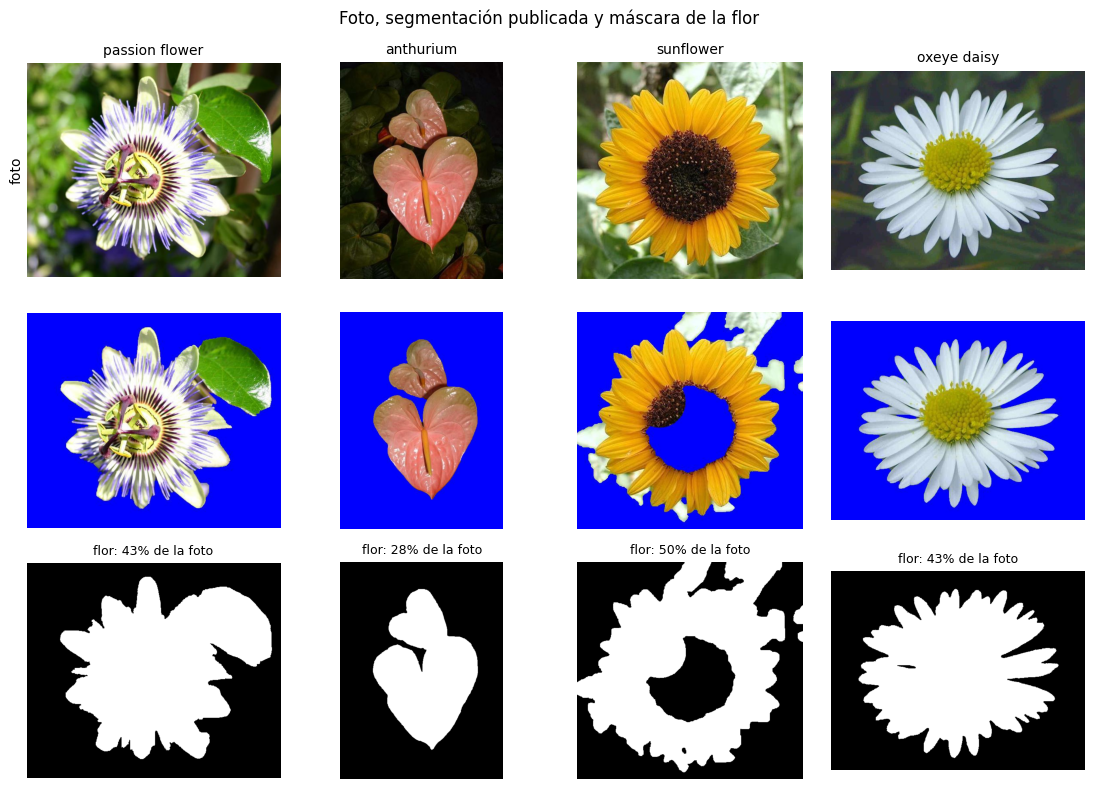

In [12]:
def es_fondo(seg):
    """seg: arreglo [alto, ancho, 3] de una segmentación. True donde está el azul del fondo."""
    return (seg[..., 2] > 200) & (seg[..., 0] < 60) & (seg[..., 1] < 60)


ejemplos = [0, 2000, 5414, 6224]
fig, ejes = plt.subplots(3, 4, figsize=(11, 8))
for j, i in enumerate(ejemplos):
    s = Image.open(f"{CARPETA}/segmim/segmim_{i + 1:05d}.jpg").convert("RGB")
    ejes[0, j].imshow(abrir(i, 500))
    ejes[0, j].set_title(NOMBRES[etiquetas[i]], fontsize=10)
    ejes[1, j].imshow(s)
    ejes[2, j].imshow(~es_fondo(np.array(s)), cmap="gray")
    ejes[2, j].set_title(f"flor: {(~es_fondo(np.array(s))).mean():.0%} de la foto", fontsize=9)
for eje in ejes.flat:
    eje.axis("off")
ejes[0, 0].text(-40, 250, "foto", rotation=90, va="center")
plt.suptitle("Foto, segmentación publicada y máscara de la flor")
plt.tight_layout()
plt.show()

La máscara (blanco = flor) sigue bien el contorno en estos ejemplos. La sección siguiente mide cuántas segmentaciones fallan.

## 6. Leer las 8.189 fotos una vez

Decodificar una foto JPEG es lo más caro de todo el notebook, así que leemos cada foto y su segmentación **una sola vez** y guardamos en memoria solo lo que necesitan los descriptores:

- una miniatura en color de 32 × 32, para el color (y su versión en HSV);
- la máscara de la flor a ese mismo tamaño;
- un **recorte** en gris de 128 × 128 de la caja más chica que contiene a la flor, para la forma, como hace el artículo con HOG (sección 3.1);
- la foto entera en gris a 128 × 128, para medir en la sección 12 si recortar ayuda.

Con `draft`, cada foto se decodifica a la mitad de su tamaño (lado corto de 250) y cada segmentación a un cuarto. Si una máscara tiene menos del 1% de la foto, la segmentación falló: en ese caso usamos la foto entera.

In [13]:
LADO_COLOR = 32
LADO_FORMA = 128


def caja_de_la_flor(mascara, escala, ancho, alto):
    """La caja más chica que contiene a la flor, en coordenadas de la foto."""
    filas = np.flatnonzero(mascara.any(axis=1))
    columnas = np.flatnonzero(mascara.any(axis=0))
    return (int(columnas[0] * escala), int(filas[0] * escala),
            min(ancho, int((columnas[-1] + 1) * escala)), min(alto, int((filas[-1] + 1) * escala)))


miniaturas = torch.zeros(N, 3, LADO_COLOR, LADO_COLOR, dtype=torch.uint8)
hsv = torch.zeros(N, 3, LADO_COLOR, LADO_COLOR, dtype=torch.uint8)
primer_plano = torch.zeros(N, LADO_COLOR, LADO_COLOR, dtype=torch.bool)
recortes = torch.zeros(N, LADO_FORMA, LADO_FORMA, dtype=torch.uint8)
enteras = torch.zeros(N, LADO_FORMA, LADO_FORMA, dtype=torch.uint8)
fallida = torch.zeros(N, dtype=torch.bool)

inicio = time.perf_counter()
for i in range(N):
    foto = abrir(i, 200)                                         # lado corto de 250
    seg = Image.open(f"{CARPETA}/segmim/segmim_{i + 1:05d}.jpg")
    seg.draft("RGB", (100, 100))                                 # lado corto de 125
    mascara = ~es_fondo(np.array(seg.convert("RGB")))
    if mascara.mean() < 0.01:
        fallida[i] = True
        mascara[:] = True

    chica = foto.resize((LADO_COLOR, LADO_COLOR), Image.BILINEAR)
    miniaturas[i] = torch.from_numpy(np.array(chica)).permute(2, 0, 1)
    hsv[i] = torch.from_numpy(np.array(chica.convert("HSV"))).permute(2, 0, 1)
    mascara_chica = np.array(Image.fromarray(mascara).resize((LADO_COLOR, LADO_COLOR), Image.NEAREST))
    primer_plano[i] = torch.from_numpy(mascara_chica) if mascara_chica.any() else True

    gris = foto.convert("L")
    caja = caja_de_la_flor(mascara, foto.width / mascara.shape[1], foto.width, foto.height)
    recortes[i] = torch.from_numpy(np.array(gris.crop(caja).resize((LADO_FORMA, LADO_FORMA), Image.BILINEAR)))
    enteras[i] = torch.from_numpy(np.array(gris.resize((LADO_FORMA, LADO_FORMA), Image.BILINEAR)))

print(f"leídas {N} fotos y segmentaciones en {time.perf_counter() - inicio:.0f} s")
print(f"segmentaciones fallidas: {fallida.sum().item()} ({fallida.float().mean():.1%})")
print(f"la flor ocupa en promedio el {primer_plano[~fallida].float().mean():.0%} de la miniatura")

leídas 8189 fotos y segmentaciones en 68 s
segmentaciones fallidas: 220 (2.7%)
la flor ocupa en promedio el 37% de la miniatura


Un 2.7% de las segmentaciones publicadas no marcan ningún píxel como flor: toda la imagen quedó azul. Veamos algunas:

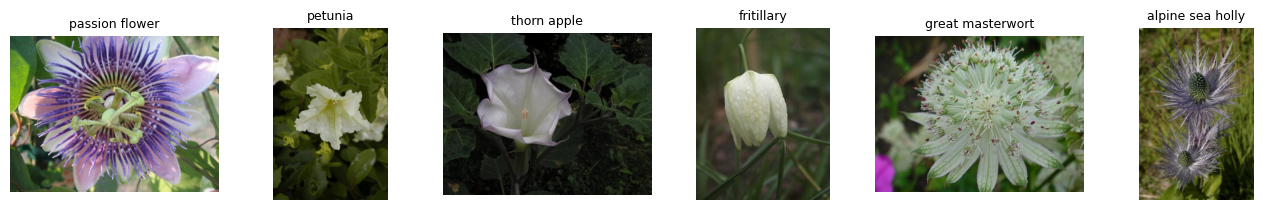

In [14]:
mostrar(torch.where(fallida)[0][::40][:6].tolist())

Son fotos donde la flor ocupa casi todo el cuadro, o que muestran muchas flores chicas, o un racimo: casos donde "la flor" y "el fondo" no se separan con un contorno. El artículo no menciona estos casos; el número es nuestro.

## 7. Color: palabras visuales en HSV

**Por qué HSV.** El artículo describe el color con los valores HSV de cada píxel (tono, saturación y brillo; *hue, saturation, value*) en vez de RGB, porque HSV es menos sensible a cambios de iluminación y así debería tolerar fotos tomadas con distinto clima y a distintas horas (sección 3.1). Lo comprobamos oscureciendo una foto a la mitad y midiendo cuánto cambia cada canal. En Pillow, el tono va de 0 a 255 como una versión escalada de 0° a 360° ([modos de imagen de Pillow](https://pillow.readthedocs.io/en/stable/handbook/concepts.html#modes)), así que es un ángulo: 250 y 5 están cerca.

In [15]:
girasol = abrir(PAGINA_A_INDICE := 5414 - 1, 200) if False else abrir(5413, 200)
oscuro = girasol.point(lambda v: v // 2)

rgb_a, rgb_b = np.array(girasol, dtype=float), np.array(oscuro, dtype=float)
hsv_a, hsv_b = np.array(girasol.convert("HSV"), dtype=float), np.array(oscuro.convert("HSV"), dtype=float)
cambio_tono = np.abs(hsv_a[..., 0] - hsv_b[..., 0])
cambio_tono = np.minimum(cambio_tono, 256 - cambio_tono)        # el tono da la vuelta: 250 y 5 están cerca

for nombre, cambio in [("R", np.abs(rgb_a[..., 0] - rgb_b[..., 0])), ("G", np.abs(rgb_a[..., 1] - rgb_b[..., 1])),
                       ("B", np.abs(rgb_a[..., 2] - rgb_b[..., 2])), ("tono (H)", cambio_tono),
                       ("saturación (S)", np.abs(hsv_a[..., 1] - hsv_b[..., 1])), ("brillo (V)", np.abs(hsv_a[..., 2] - hsv_b[..., 2]))]:
    print(f"{nombre:15s} cambia en promedio {cambio.mean():5.1f} de 255")

R               cambia en promedio  74.0 de 255
G               cambia en promedio  60.3 de 255
B               cambia en promedio  32.2 de 255
tono (H)        cambia en promedio   0.4 de 255
saturación (S)  cambia en promedio   1.0 de 255
brillo (V)      cambia en promedio  78.7 de 255


Al oscurecer la foto a la mitad, los tres canales RGB cambian mucho, y el brillo (V) carga con todo el cambio. El tono y la saturación casi no se mueven: el amarillo del girasol sigue siendo el mismo amarillo, solo que más oscuro. Si el descriptor de color le da peso al tono y la saturación, dos fotos de la misma flor con distinta luz quedan parecidas.

**Palabras visuales.** El artículo agrupa los valores HSV de los píxeles con *k-means*. Cada grupo es una "palabra visual" (un color típico), y cada foto se describe con un histograma: qué fracción de sus píxeles cae en cada palabra (sección 3.1). Es la misma idea que describir un texto contando cuántas veces aparece cada palabra.

*k-means* busca $K$ centros de manera que cada punto quede cerca de su centro más cercano. Alterna dos pasos: asignar cada punto al centro más cercano, y mover cada centro al promedio de sus puntos. Lo escribimos en pocas líneas:

In [16]:
def k_means(puntos, k, iteraciones=20, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    centros = puntos[torch.randperm(len(puntos), generator=generador)[:k]].clone()   # k puntos al azar
    for _ in range(iteraciones):
        asignacion = torch.cdist(puntos, centros).argmin(dim=1)                       # centro más cercano
        suma = torch.zeros_like(centros).index_add_(0, asignacion, puntos)
        cuantos = torch.bincount(asignacion, minlength=k)
        con_puntos = cuantos > 0
        centros[con_puntos] = suma[con_puntos] / cuantos[con_puntos, None]           # promedio de cada grupo
    return centros

El vocabulario se aprende solo con las fotos de **entrenamiento**, y solo con los píxeles de la flor. El artículo eligió el número de palabras en la validación, buscando entre 100 y 5.000, y se quedó con 1.000 (sección 4.1). Nosotros usamos 100 para que el notebook sea rápido (el ejercicio 1 propone variarlo).

398651 píxeles de flor en entrenamiento; k-means con 100000 de ellos en 2.5 s


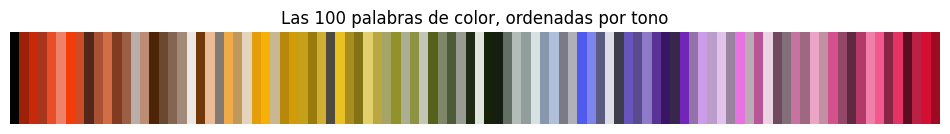

In [17]:
K_COLOR = 100
pixeles_hsv = hsv.float().permute(0, 2, 3, 1).reshape(N, -1, 3) / 255      # [8189, 1024 píxeles, 3]
mascara_plana = primer_plano.reshape(N, -1)                                  # [8189, 1024]

pixeles_flor = pixeles_hsv[entrenamiento][mascara_plana[entrenamiento]]
muestra = pixeles_flor[torch.randperm(len(pixeles_flor), generator=torch.Generator().manual_seed(0))[:100_000]]
inicio = time.perf_counter()
palabras_color = k_means(muestra, K_COLOR)
print(f"{len(pixeles_flor)} píxeles de flor en entrenamiento; k-means con {len(muestra)} de ellos "
      f"en {time.perf_counter() - inicio:.1f} s")

# el vocabulario como paleta, ordenado por tono
paleta = Image.fromarray((palabras_color[palabras_color[:, 0].argsort()] * 255).round().byte()[None].numpy(), "HSV")
fig, eje = plt.subplots(figsize=(12, 1.2))
eje.imshow(np.array(paleta.convert("RGB")), aspect="auto")
eje.set_title(f"Las {K_COLOR} palabras de color, ordenadas por tono")
eje.axis("off")
plt.show()

Las palabras cubren los colores de las flores: muchos rojos, rosados, amarillos y violetas, y también verdes y marrones, que vienen de tallos, hojas y centros que la segmentación deja dentro de la flor.

Ahora cada píxel de cada foto recibe su palabra más cercana, y contamos. Hacemos dos histogramas por foto: uno con los píxeles de la flor, como el artículo, y otro con la foto entera, para la sección 12.

In [18]:
def asignar_palabras(descriptores, palabras, trozo=512):
    """descriptores: [fotos, n, d]. Devuelve el índice de la palabra más cercana de cada uno: [fotos, n]."""
    return torch.cat([torch.cdist(descriptores[i:i + trozo], palabras).argmin(dim=-1)
                      for i in range(0, len(descriptores), trozo)])


def histogramas(palabras_de_cada_una, k, pesos=None):
    """Cuenta cuántas veces aparece cada palabra en cada foto y normaliza para que sume 1."""
    if pesos is None:
        pesos = torch.ones_like(palabras_de_cada_una, dtype=torch.float)
    h = torch.zeros(len(palabras_de_cada_una), k).scatter_add_(1, palabras_de_cada_una, pesos)
    return h / h.sum(dim=1, keepdim=True)


inicio = time.perf_counter()
palabra_de_cada_pixel = asignar_palabras(pixeles_hsv, palabras_color)
color_flor = histogramas(palabra_de_cada_pixel, K_COLOR, mascara_plana.float())
color_entera = histogramas(palabra_de_cada_pixel, K_COLOR)
print(f"histogramas de color: {tuple(color_flor.shape)} en {time.perf_counter() - inicio:.1f} s")

histogramas de color: (8189, 100) en 11.0 s


**La distancia χ².** Para comparar dos histogramas, el artículo usa la distancia χ² simétrica (sección 3.2):

$$\chi^2(x, y) = \frac{1}{2}\sum_i \frac{(x_i - y_i)^2}{x_i + y_i}$$

Se parece a la distancia euclidiana al cuadrado, pero cada diferencia se divide por el tamaño de las barras. Una diferencia de 0.05 pesa mucho entre barras chicas (0.01 contra 0.06) y poco entre barras grandes (0.40 contra 0.45). Como los histogramas suman 1, vale entre 0 (iguales) y 1 (sin ninguna palabra en común). Usando que $(x - y)^2 = (x + y)^2 - 4xy$, se puede escribir como $1 - 2\sum_i x_i y_i / (x_i + y_i)$, que es más rápida de calcular:

In [19]:
def chi2(A, B, trozo=128):
    """Distancia χ² entre cada fila de A y cada fila de B (histogramas que suman 1)."""
    salida = torch.empty(len(A), len(B))
    for i in range(0, len(A), trozo):
        a = A[i:i + trozo, None, :]
        producto = a * B[None]
        suma = (a + B[None]).clamp_(min=1e-10)
        salida[i:i + trozo] = 1 - 2 * (producto / suma).sum(dim=-1)
    return salida


# comprobación contra la fórmula directa
x, y = color_flor[:5], color_flor[100:103]
directa = 0.5 * ((x[:, None] - y[None]) ** 2 / (x[:, None] + y[None]).clamp(min=1e-10)).sum(-1)
print("¿Coincide con la fórmula directa?", torch.allclose(chi2(x, y), directa, atol=1e-6))

¿Coincide con la fórmula directa? True


Miramos tres fotos: dos girasoles y una margarita (*oxeye daisy*), con sus histogramas pintados con el color de cada palabra.

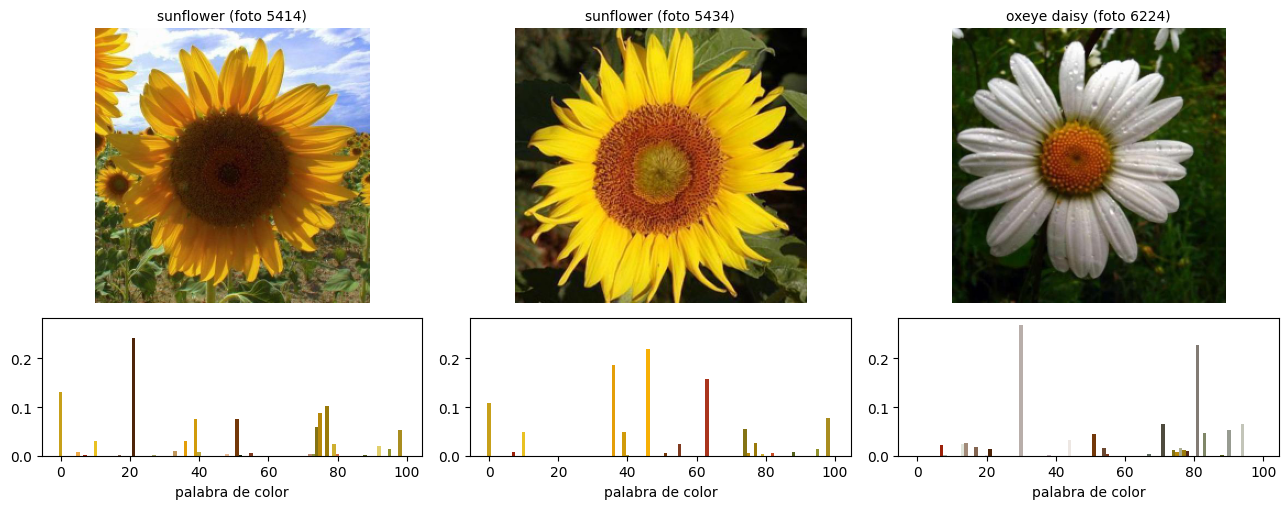

χ² girasol-girasol : 0.516
χ² girasol-margarita: 0.846 y 0.926


In [20]:
trio = [5413, 5433, 6223]          # dos girasoles y una margarita
fig, ejes = plt.subplots(2, 3, figsize=(13, 5.2), gridspec_kw={"height_ratios": [2, 1]})
colores_rgb = np.array(Image.fromarray((palabras_color * 255).round().byte()[None].numpy(), "HSV").convert("RGB"))[0] / 255
for j, i in enumerate(trio):
    ejes[0, j].imshow(abrir(i))
    ejes[0, j].set_title(f"{NOMBRES[etiquetas[i]]} (foto {i + 1})", fontsize=10)
    ejes[0, j].axis("off")
    ejes[1, j].bar(range(K_COLOR), color_flor[i], color=colores_rgb, width=1.0)
    ejes[1, j].set_ylim(0, color_flor[trio].max() * 1.05)
    ejes[1, j].set_xlabel("palabra de color")
plt.tight_layout()
plt.show()

d = chi2(color_flor[trio], color_flor[trio])
print(f"χ² girasol-girasol : {d[0, 1]:.3f}")
print(f"χ² girasol-margarita: {d[0, 2]:.3f} y {d[1, 2]:.3f}")

Los dos girasoles reparten sus píxeles entre las mismas palabras amarillas y marrones, y su distancia es mucho menor que la de cualquiera de ellos con la margarita, que es casi toda blanca.

## 8. Forma: gradientes locales y HOG

El color no basta: hay flores del mismo color con formas distintas. Los otros tres descriptores del artículo miran la forma, y los tres se construyen con **gradientes**: cuánto y en qué dirección cambia el brillo de un píxel al siguiente. En un borde (el contorno de un pétalo, una vena) el gradiente es grande y apunta perpendicular al borde.

Calculamos el gradiente con diferencias entre vecinos: el horizontal es el píxel de la derecha menos el de la izquierda, y el vertical, el de abajo menos el de arriba. De ahí salen la magnitud y el ángulo:

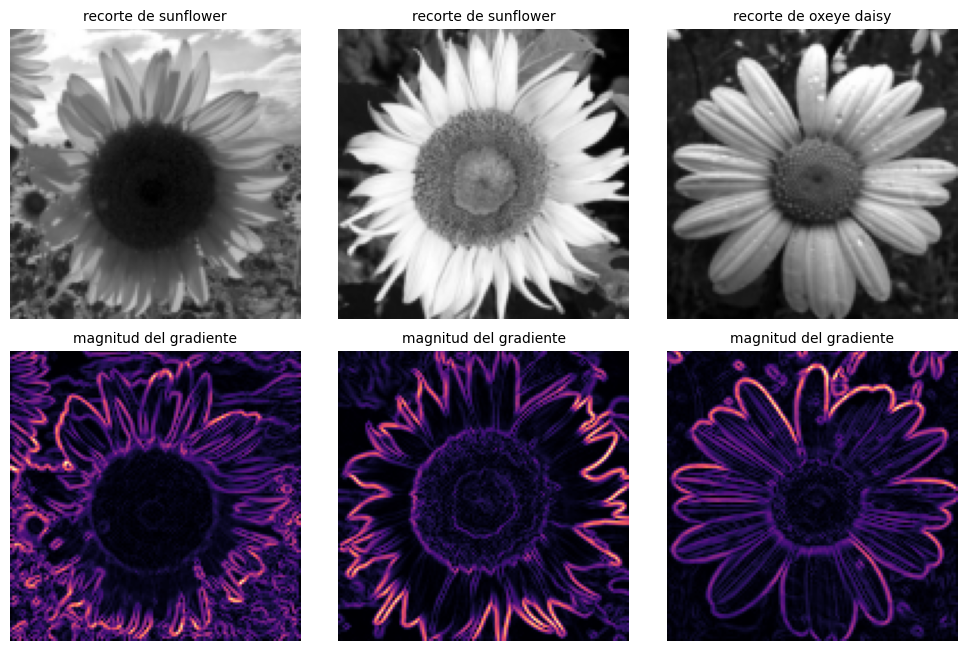

In [21]:
def gradientes(imagenes):
    """imagenes: [n, alto, ancho] en gris (0-255). Devuelve magnitud y ángulo (radianes, entre 0 y 2π)."""
    x = imagenes.float() / 255
    gx = torch.zeros_like(x)
    gy = torch.zeros_like(x)
    gx[:, :, 1:-1] = x[:, :, 2:] - x[:, :, :-2]
    gy[:, 1:-1, :] = x[:, 2:, :] - x[:, :-2, :]
    return torch.sqrt(gx ** 2 + gy ** 2), torch.atan2(gy, gx) % (2 * np.pi)


magnitud, angulo = gradientes(recortes[trio])
fig, ejes = plt.subplots(2, 3, figsize=(10, 6.6))
for j in range(3):
    ejes[0, j].imshow(recortes[trio[j]], cmap="gray")
    ejes[0, j].set_title(f"recorte de {NOMBRES[etiquetas[trio[j]]]}", fontsize=10)
    ejes[1, j].imshow(magnitud[j], cmap="magma")
    ejes[1, j].set_title("magnitud del gradiente", fontsize=10)
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

Arriba, los recortes de 128 × 128 en gris: la caja de la flor, estirada al cuadrado. Abajo, la magnitud del gradiente: los bordes de los pétalos y la textura del centro se encienden; las zonas lisas quedan oscuras.

**Gradientes locales (nuestra versión de SIFT).** El descriptor más fuerte del artículo es SIFT calculado en una grilla regular sobre la flor: en cada punto, un vector de 128 números que resume las orientaciones de los gradientes de su vecindario, solo con el gris y no el color (sección 3.1). Nuestra versión simplificada:

1. Dividimos el recorte en celdas de 6 × 6 píxeles, y en cada celda sumamos las magnitudes de los gradientes según su orientación, en 8 direcciones.
2. Cada ventana de 4 × 4 celdas, desplazándose de 2 en 2 celdas, da un vector de 4 × 4 × 8 = 128 números, que normalizamos.

Salen 81 descriptores por foto. A diferencia de SIFT, los nuestros no son invariantes a la rotación, trabajan a una sola escala y sobre una foto 4 veces más chica que la del artículo.

In [22]:
def descriptores_locales(imagenes, celda=6, orientaciones=8):
    magnitud, angulo = gradientes(imagenes)
    caja = (angulo / (2 * np.pi / orientaciones)).long().clamp(max=orientaciones - 1)
    por_orientacion = torch.zeros(len(imagenes), orientaciones, *imagenes.shape[1:])
    por_orientacion.scatter_(1, caja[:, None], magnitud[:, None])                 # [n, 8, 128, 128]
    celdas = F.avg_pool2d(por_orientacion, celda) * celda * celda                 # suma por celda: [n, 8, 21, 21]
    ventanas = F.unfold(celdas, kernel_size=4, stride=2).transpose(1, 2)          # [n, 81, 128]
    return ventanas / (ventanas.norm(dim=-1, keepdim=True) + 1e-6)


print("descriptores de una foto:", tuple(descriptores_locales(recortes[:1]).shape))

descriptores de una foto: (1, 81, 128)


Igual que con el color, cada descriptor se reemplaza por su palabra visual más cercana y cada foto queda como un histograma. El vocabulario sale de 60.000 descriptores de las fotos de entrenamiento, con 200 palabras (el artículo usó 8.000, sección 4.1). Calculamos los descriptores por trozos, porque los de las 8.189 fotos juntos ocuparían más de 300 MB:

In [23]:
K_GRADIENTES = 200
inicio = time.perf_counter()
de_entrenamiento = descriptores_locales(recortes[entrenamiento]).reshape(-1, 128)
muestra = de_entrenamiento[torch.randperm(len(de_entrenamiento), generator=torch.Generator().manual_seed(0))[:60_000]]
palabras_gradientes = k_means(muestra, K_GRADIENTES, iteraciones=15)

palabra_de_cada_descriptor = torch.cat([asignar_palabras(descriptores_locales(recortes[i:i + 256]), palabras_gradientes)
                                        for i in range(0, N, 256)])
gradientes_locales = histogramas(palabra_de_cada_descriptor, K_GRADIENTES)
print(f"histogramas de gradientes locales: {tuple(gradientes_locales.shape)} en {time.perf_counter() - inicio:.0f} s")

histogramas de gradientes locales: (8189, 200) en 19 s


**HOG** (*histogram of oriented gradients*). El artículo lo calcula sobre toda la región de la flor, dentro de la caja más chica que la contiene, y sin hacerlo invariante a la rotación, para capturar la distribución espacial de la flor, como la disposición general de los pétalos (sección 3.1). Nuestra versión divide el recorte en una grilla de 4 × 4 celdas de 32 píxeles y hace en cada celda un histograma de 9 orientaciones, sin distinguir el sentido (0° y 180° son la misma orientación de borde). Son 4 × 4 × 9 = 144 números que dicen *dónde* hay bordes de *qué* orientación. El artículo, además, convierte HOG en palabras visuales; nosotros usamos el vector directamente, normalizado para que sume 1.

In [24]:
def hog(imagenes, celda=32, orientaciones=9, trozo=512):
    partes = []
    for i in range(0, len(imagenes), trozo):
        magnitud, angulo = gradientes(imagenes[i:i + trozo])
        angulo = angulo % np.pi                                                     # sin sentido: 0 a π
        caja = (angulo / (np.pi / orientaciones)).long().clamp(max=orientaciones - 1)
        por_orientacion = torch.zeros(len(magnitud), orientaciones, *magnitud.shape[1:])
        por_orientacion.scatter_(1, caja[:, None], magnitud[:, None])
        h = F.avg_pool2d(por_orientacion, celda).flatten(2)                         # [n, 9, 16 celdas]
        h = h / (h.sum(dim=1, keepdim=True) + 1e-6)                                 # normaliza cada celda
        partes.append(h.flatten(1))
    h = torch.cat(partes)
    return h / h.sum(dim=1, keepdim=True)


inicio = time.perf_counter()
hog_recorte = hog(recortes)
hog_entera = hog(enteras)
print(f"HOG: {tuple(hog_recorte.shape)} en {time.perf_counter() - inicio:.1f} s")

HOG: (8189, 144) en 11.6 s


## 9. Un primer clasificador: el vecino más cercano

Con un histograma por foto, el clasificador más simple es el **vecino más cercano**: a cada foto de prueba le asignamos la clase de la foto de referencia (entrenamiento y validación, 20 por clase) más parecida. Es el que usa el artículo en su comparación con trabajos anteriores, con χ² como distancia (sección 6).

Antes, dos líneas base. La primera es el azar de la sección 4. La segunda, el vecino más cercano sobre los **píxeles crudos**: las miniaturas de 32 × 32 en color, comparadas con la distancia euclidiana. Si los descriptores no superan a los píxeles, no sirven de nada.

In [25]:
def vecino_mas_cercano(distancias):
    """distancias: [fotos de prueba, fotos de referencia]."""
    return etiquetas[referencia][distancias.argmin(dim=1)]


pixeles = miniaturas.float().flatten(1) / 255
informar("píxeles crudos, vecino más cercano", vecino_mas_cercano(torch.cdist(pixeles[prueba], pixeles[referencia])))

píxeles crudos, vecino más cercano       por clase  15.1%   por foto  13.9%


0.15094779431819916

Los píxeles crudos aciertan 14.8% por clase, quince veces el azar: las fotos de una misma clase comparten algo de color y composición. Calculamos ahora las distancias χ² de **todas** las fotos contra las 2.040 de referencia, una vez por descriptor, y las guardamos: las usaremos para todos los clasificadores que siguen.

In [26]:
descriptores = {
    "color": color_flor,
    "gradientes locales": gradientes_locales,
    "HOG": hog_recorte,
    "color (foto entera)": color_entera,
    "HOG (foto entera)": hog_entera,
}
inicio = time.perf_counter()
distancias = {nombre: chi2(h, h[referencia]) for nombre, h in descriptores.items()}      # cada una: [8189, 2040]
print(f"distancias χ² en {time.perf_counter() - inicio:.0f} s")

for nombre in ["color", "gradientes locales", "HOG"]:
    informar(f"{nombre}, vecino más cercano", vecino_mas_cercano(distancias[nombre][prueba]))

distancias χ² en 42 s


color, vecino más cercano                por clase  29.0%   por foto  28.0%
gradientes locales, vecino más cercano   por clase   8.2%   por foto   7.1%


HOG, vecino más cercano                  por clase  11.0%   por foto   8.8%


El color solo ya duplica a los píxeles crudos. Los dos descriptores de forma quedan por debajo: nuestras versiones son muy simples, y con el vecino más cercano una sola foto de referencia parecida por casualidad decide la respuesta. El clasificador del artículo aprovecha mejor la información, comparando cada foto con todas las de referencia a la vez.

## 10. Kernels: de distancias a similitudes

El artículo convierte cada distancia χ² en una **similitud** (sección 3.2):

$$K(x, y) = \exp\left(-\gamma\, \chi^2(x, y)\right), \qquad \gamma = \frac{1}{\text{promedio de } \chi^2 \text{ entre las fotos de entrenamiento}}$$

Dos fotos iguales tienen similitud 1, y la similitud baja hacia 0 a medida que se alejan. $\gamma$ fija la escala: una distancia del tamaño de la distancia típica da una similitud de $e^{-1} \approx 0.37$. A esta función se le llama **kernel**.

Con los kernels, el artículo entrena una SVM. Nosotros usamos otro clasificador con kernel que se resuelve con una sola línea de álgebra lineal, la **regresión ridge con kernel**: cada foto se representa por sus similitudes con las 2.040 fotos de referencia, y la puntuación de cada clase es una combinación lineal de esas similitudes,

$$\text{puntuación}_c(x) = \sum_j \alpha_{jc}\, K(x, x_j).$$

Es una capa lineal, como `nn.Linear`, cuyas entradas son similitudes. En vez de entrenarla con descenso de gradiente, elegimos los pesos $\alpha$ que mejor reproducen las etiquetas (uno para la clase correcta, cero para las demás) con una penalización $\lambda$ sobre su tamaño, y eso tiene solución exacta: $\alpha = (K + \lambda I)^{-1} Y$. `torch.linalg.solve` la calcula sin invertir la matriz. La predicción es la clase de mayor puntuación.

In [27]:
def a_kernel(d):
    gamma = 1 / d[entrenamiento][:, EN_REF].mean()          # escala: la distancia típica entre fotos de entrenamiento
    return torch.exp(-gamma * d)


def ajustar(K_ref, y_ref, lam):
    Y = F.one_hot(y_ref, 102).float()
    return torch.linalg.solve(K_ref + lam * torch.eye(len(K_ref)), Y)


def elegir_y_probar(K, lambdas=(0.01, 0.1, 1.0)):
    """Elige λ entrenando con entrenamiento y midiendo en validación; reentrena con las 2.040 y predice la prueba."""
    en_validacion = {}
    for lam in lambdas:
        alfa = ajustar(K[entrenamiento][:, EN_REF], etiquetas[entrenamiento], lam)
        prediccion = (K[validacion][:, EN_REF] @ alfa).argmax(dim=1)
        en_validacion[lam] = exactitud_por_clase(prediccion, validacion).mean().item()
    mejor = max(en_validacion, key=en_validacion.get)
    alfa = ajustar(K[referencia], etiquetas[referencia], mejor)
    puntuaciones = K[prueba] @ alfa
    return mejor, en_validacion[mejor], puntuaciones


kernels = {nombre: a_kernel(d) for nombre, d in distancias.items()}
puntuaciones = {}
for nombre in ["color", "gradientes locales", "HOG"]:
    lam, en_val, puntuaciones[nombre] = elegir_y_probar(kernels[nombre])
    print(f"{nombre}: λ = {lam} (validación {en_val:.1%})")
    informar(f"{nombre}, kernel χ²", puntuaciones[nombre].argmax(dim=1))

color: λ = 0.1 (validación 29.9%)
color, kernel χ²                         por clase  37.9%   por foto  35.8%


gradientes locales: λ = 0.01 (validación 11.4%)
gradientes locales, kernel χ²            por clase  13.5%   por foto  11.3%


HOG: λ = 1.0 (validación 16.3%)
HOG, kernel χ²                           por clase  20.2%   por foto  17.9%


Con el mismo descriptor, el clasificador con kernel le saca bastante más que el vecino más cercano a las tres características. El color sigue siendo la mejor; los gradientes locales y HOG quedan alrededor del 20%.

Comparemos con la tabla 1 del artículo, que mide lo mismo (exactitud por clase en la prueba oficial):

| Característica | Artículo | Aquí |
|---|---|---|
| Color (HSV) | 43.0% | 38.8% |
| SIFT dentro de la flor / gradientes locales | 55.1% | 21.1% |
| HOG | 49.6% | 17.7% |

El color queda cerca. La forma queda muy lejos, y no es sorprendente: nuestros descriptores de forma trabajan con recortes de 128 píxeles en vez de fotos de 500, con 81 descriptores por foto en vez de una grilla densa, sin invariancia a la rotación, con 200 palabras en vez de 8.000, y la ventana fija del recorte incluye fondo. El color, en cambio, no necesita resolución: el amarillo de un girasol se ve igual en 32 × 32.

## 11. Combinar características

La tesis del artículo es que cada característica mira un aspecto distinto de la flor, y que combinarlas supera a la mejor sola. La forma de combinar es sumar los kernels con pesos:

$$K(x, y) = \sum_f \beta_f \exp\left(-\gamma_f\, \chi^2_f(x, y)\right)$$

En el artículo, los pesos $\beta_f$ se aprenden **para cada clase** con el método de Varma y Ray (secciones 3.2 y 4.1). Nosotros probamos dos versiones más simples: pesos iguales, y un solo juego de pesos para todas las clases, elegido en la validación entre 0, 1 y 2 para cada característica.

In [28]:
tres = ["color", "gradientes locales", "HOG"]

K_igual = sum(kernels[f] for f in tres) / 3
lam, en_val, puntuaciones["iguales"] = elegir_y_probar(K_igual)
print(f"pesos iguales: λ = {lam} (validación {en_val:.1%})")
informar("combinación, pesos iguales", puntuaciones["iguales"].argmax(dim=1))

# un juego de pesos elegido en la validación
mejor = None
for b0 in [0, 1, 2]:
    for b1 in [0, 1, 2]:
        for b2 in [0, 1, 2]:
            if b0 + b1 + b2 == 0:
                continue
            K = (b0 * kernels[tres[0]] + b1 * kernels[tres[1]] + b2 * kernels[tres[2]]) / (b0 + b1 + b2)
            for lam in [0.01, 0.1, 1.0]:
                alfa = ajustar(K[entrenamiento][:, EN_REF], etiquetas[entrenamiento], lam)
                acierto = exactitud_por_clase((K[validacion][:, EN_REF] @ alfa).argmax(dim=1), validacion).mean().item()
                if mejor is None or acierto > mejor[0]:
                    mejor = (acierto, (b0, b1, b2), lam)

acierto, pesos, lam = mejor
print(f"\nmejores pesos en validación: color {pesos[0]}, gradientes {pesos[1]}, HOG {pesos[2]}, λ = {lam} "
      f"(validación {acierto:.1%})")
K_pesos = sum(b * kernels[f] for b, f in zip(pesos, tres)) / sum(pesos)
puntuaciones["pesos"] = K_pesos[prueba] @ ajustar(K_pesos[referencia], etiquetas[referencia], lam)
informar("combinación, pesos elegidos en validación", puntuaciones["pesos"].argmax(dim=1))

pesos iguales: λ = 0.1 (validación 40.0%)
combinación, pesos iguales               por clase  48.8%   por foto  45.1%



mejores pesos en validación: color 1, gradientes 1, HOG 2, λ = 1.0 (validación 40.6%)


combinación, pesos elegidos en validación por clase  47.0%   por foto  43.0%


0.4702894687652588

La combinación con pesos iguales pasa de 38.8% (el color solo) a 50.2% por clase. Elegir los pesos en la validación casi no cambia nada en la prueba: el mejor juego (color 1, gradientes 2, HOG 2) da 50.4%. Lo que importa es combinar.

Es la conclusión del artículo, reproducida con piezas mucho más pobres: los gradientes locales y HOG solos son la mitad de buenos que el color, pero aportan información que el color no tiene. Todos los resultados juntos:

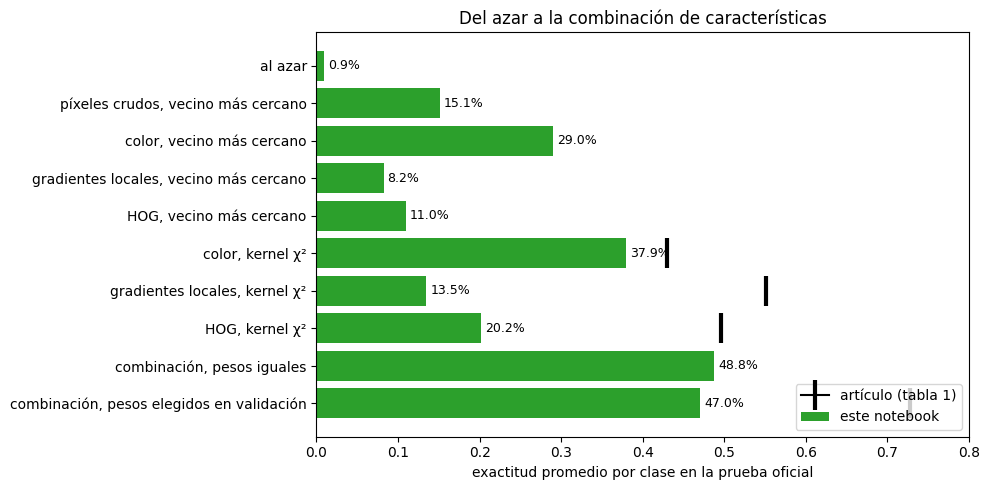

In [29]:
nombres = list(resultados)
valores = [resultados[n] for n in nombres]
articulo = {"color, kernel χ²": 0.430, "gradientes locales, kernel χ²": 0.551, "HOG, kernel χ²": 0.496,
            "combinación, pesos elegidos en validación": 0.728}

fig, eje = plt.subplots(figsize=(10, 5))
y = np.arange(len(nombres))
eje.barh(y, valores, color="tab:green", label="este notebook")
for k, n in enumerate(nombres):
    if n in articulo:
        eje.plot(articulo[n], k, marker="|", markersize=22, markeredgewidth=3, color="black",
                 label="artículo (tabla 1)" if n == "color, kernel χ²" else None)
    eje.text(valores[k] + 0.005, k, f"{valores[k]:.1%}", va="center", fontsize=9)
eje.set_yticks(y, nombres)
eje.invert_yaxis()
eje.set_xlabel("exactitud promedio por clase en la prueba oficial")
eje.set_xlim(0, 0.8)
eje.legend(loc="lower right")
eje.set_title("Del azar a la combinación de características")
plt.tight_layout()
plt.show()

Las marcas negras son las cifras de la tabla 1 del artículo para la característica equivalente. (Para los gradientes locales, la marca es la de SIFT dentro de la flor, que es lo que imitan.)

## 12. ¿Ayuda segmentar?

El artículo segmenta para que, como en Caltech 101, en cada imagen quede solo el objeto y se elimine el fondo (sección 1). ¿Lo comprobamos? Comparamos cada descriptor calculado sobre la flor contra el mismo descriptor calculado sobre la foto entera. Es una decisión de diseño, así que la tomamos en la **validación**, sin mirar la prueba:

In [30]:
def en_validacion(K, lam=0.1):
    alfa = ajustar(K[entrenamiento][:, EN_REF], etiquetas[entrenamiento], lam)
    return exactitud_por_clase((K[validacion][:, EN_REF] @ alfa).argmax(dim=1), validacion).mean().item()


for flor, entera in [("color", "color (foto entera)"), ("HOG", "HOG (foto entera)")]:
    print(f"{flor:6s} solo la flor: {en_validacion(kernels[flor]):6.1%}   foto entera: {en_validacion(kernels[entera]):6.1%}")

color  solo la flor:  29.9%   foto entera:  30.8%


HOG    solo la flor:  15.6%   foto entera:  10.9%


El resultado no es parejo:

- Para **HOG**, recortar la flor ayuda: la grilla de celdas describe la disposición de los pétalos solo si la flor ocupa el cuadro. Con la foto entera, la flor cae en lugares distintos de la grilla en cada foto.
- Para el **color**, la foto entera es *mejor* que la flor sola. El fondo trae información: las hojas, el agua de los nenúfares, el cielo detrás de ciertas flores. Las fotos de una misma clase suelen tener fondos parecidos.

Un fondo informativo ayuda en este dataset, pero es un atajo: si la app del jardín botánico recibe fotos de una flor sobre un fondo distinto al habitual, ese atajo puede fallar. El artículo prefiere describir la flor, y es una decisión razonable aunque cueste exactitud en esta prueba.

## 13. Qué característica sirve para qué flor

El artículo da dos ejemplos de su tesis (secciones 1 y 3): para separar un **girasol** de una **margarita**, el color sirve y la forma no tanto; para separar un **ranúnculo** de un **diente de león**, la forma sirve y el color no. Primero miremos las cuatro:

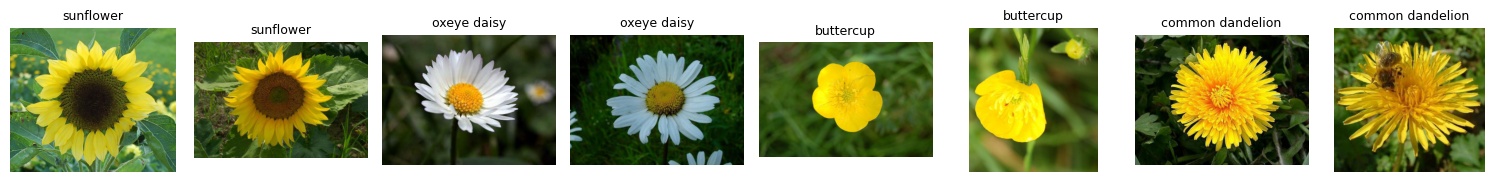

In [31]:
pares = [("sunflower", "oxeye daisy"), ("buttercup", "common dandelion")]
muestras = []
for a, b in pares:
    for nombre in (a, b):
        clase = NOMBRES.index(nombre)
        muestras += torch.where(etiquetas == clase)[0][[3, 17]].tolist()
mostrar(muestras, por_fila=8, alto=1.9)

El girasol y la margarita tienen formas parecidas (un disco central y pétalos alrededor) y colores opuestos. El ranúnculo y el diente de león son amarillos los dos, pero uno tiene cinco pétalos redondeados y el otro muchísimos pétalos finos.

Lo ponemos a prueba con un clasificador de dos clases para cada par, entrenado con las 20 fotos de referencia de cada clase y medido en sus fotos de prueba, una vez con cada característica:

In [32]:
def par_de_clases(a, b, lam=0.1):
    ca, cb = NOMBRES.index(a), NOMBRES.index(b)
    en_ref = torch.isin(etiquetas[referencia], torch.tensor([ca, cb]))
    de_prueba = prueba[torch.isin(etiquetas[prueba], torch.tensor([ca, cb]))]
    objetivo = (etiquetas[referencia][en_ref] == cb).float() * 2 - 1           # -1 para a, +1 para b
    fila = f"{a} contra {b} ({len(de_prueba)} fotos de prueba):"
    for f in tres:
        K = kernels[f]
        alfa = torch.linalg.solve(K[referencia][:, en_ref][en_ref] + lam * torch.eye(int(en_ref.sum())), objetivo)
        es_b = (K[de_prueba][:, en_ref] @ alfa) > 0
        fila += f"   {f} {(es_b == (etiquetas[de_prueba] == cb)).float().mean():6.1%}"
    print(fila)


for a, b in pares:
    par_de_clases(a, b)

sunflower contra oxeye daisy (70 fotos de prueba):   color  98.6%   gradientes locales  68.6%   HOG  81.4%
buttercup contra common dandelion (123 fotos de prueba):   color  82.9%   gradientes locales 100.0%   HOG  98.4%


Los dos ejemplos del artículo se cumplen con nuestros números:

- **girasol contra margarita**: el color acierta 98.6%; los descriptores de forma, 77% y 89%.
- **ranúnculo contra diente de león**: el color baja a 83.7%, y la forma llega a 100% con los gradientes locales y 95% con HOG.

El artículo da un ejemplo más en la sección 5: la boca de dragón (*snapdragon*) no se distingue bien por el color, porque existe en muchos colores, mientras que para la dalia naranja (*orange dahlia*) el color pesa mucho, porque tiene uno solo.

snapdragon       color    7%   gradientes locales   13%   HOG    7%


orange dahlia    color   91%   gradientes locales    9%   HOG   21%


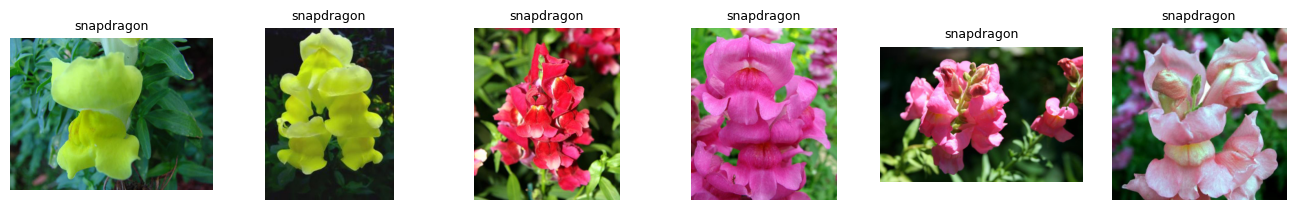

In [33]:
for nombre in ["snapdragon", "orange dahlia"]:
    clase = NOMBRES.index(nombre)
    fila = f"{nombre:14s}"
    for f in tres:
        fila += f"   {f} {exactitud_por_clase(puntuaciones[f].argmax(dim=1), prueba)[clase]:5.0%}"
    print(fila)

mostrar(torch.where(etiquetas == NOMBRES.index("snapdragon"))[0][::12][:6].tolist())

Con solo el color, la dalia naranja se acierta 89% de las veces y la boca de dragón 6%. Las fotos muestran por qué: la boca de dragón aparece en rosado, amarillo, rojo, blanco y combinaciones. Con 20 fotos de referencia, ningún histograma de color la representa bien.

## 14. Clase por clase

Usamos la combinación con pesos iguales, la más simple. Su exactitud por clase:

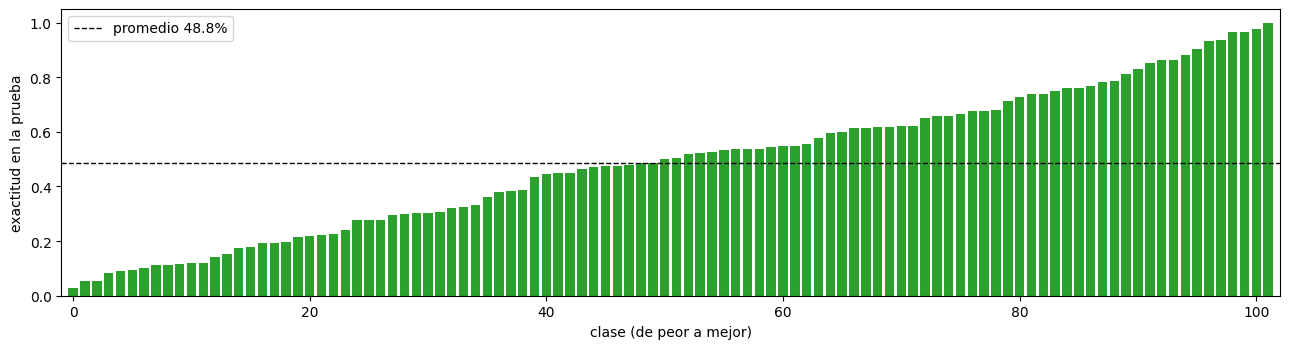

peores : sweet pea 3%, hibiscus 5%, clematis 5%, camellia 8%, sword lily 9%, carnation 9%
mejores: blanket flower 93%, orange dahlia 94%, pink-yellow dahlia? 97%, cautleya spicata 97%, bishop of llandaff 98%, osteospermum 100%

por clase 48.8%   por foto 45.1%


In [34]:
prediccion = puntuaciones["iguales"].argmax(dim=1)
por_clase = exactitud_por_clase(prediccion, prueba)
orden_clases = por_clase.argsort()

fig, eje = plt.subplots(figsize=(13, 3.6))
eje.bar(range(102), por_clase[orden_clases], color="tab:green")
eje.axhline(por_clase.mean(), color="black", linestyle="--", linewidth=1, label=f"promedio {por_clase.mean():.1%}")
eje.set_xlabel("clase (de peor a mejor)")
eje.set_ylabel("exactitud en la prueba")
eje.set_xlim(-1, 102)
eje.legend()
plt.tight_layout()
plt.show()

print("peores :", ", ".join(f"{NOMBRES[c]} {por_clase[c]:.0%}" for c in orden_clases[:6].tolist()))
print("mejores:", ", ".join(f"{NOMBRES[c]} {por_clase[c]:.0%}" for c in orden_clases[-6:].tolist()))
print(f"\npor clase {por_clase.mean():.1%}   por foto {(prediccion == etiquetas[prueba]).float().mean():.1%}")

La exactitud va de 0% a 100% según la clase. Las mejores tienen un color inconfundible y uniforme (la osteospermum, la dalia rosada y amarilla, la susana de ojos negros). Las peores son flores que existen en muchos colores (arveja de olor, camelia, clemátide, buganvilla) o con formas muy variables. Mirada por foto, la exactitud es más baja (46.6%) que por clase: varias de las clases con más fotos de prueba, como la petunia, están entre las difíciles.

Las confusiones más frecuentes:

watercress         confundida con corn poppy               27 veces
watercress         confundida con english marigold         24 veces
wallflower         confundida con black-eyed susan         20 veces
petunia            confundida con bishop of llandaff       18 veces
passion flower     confundida con love in the mist         18 veces
passion flower     confundida con globe thistle            16 veces


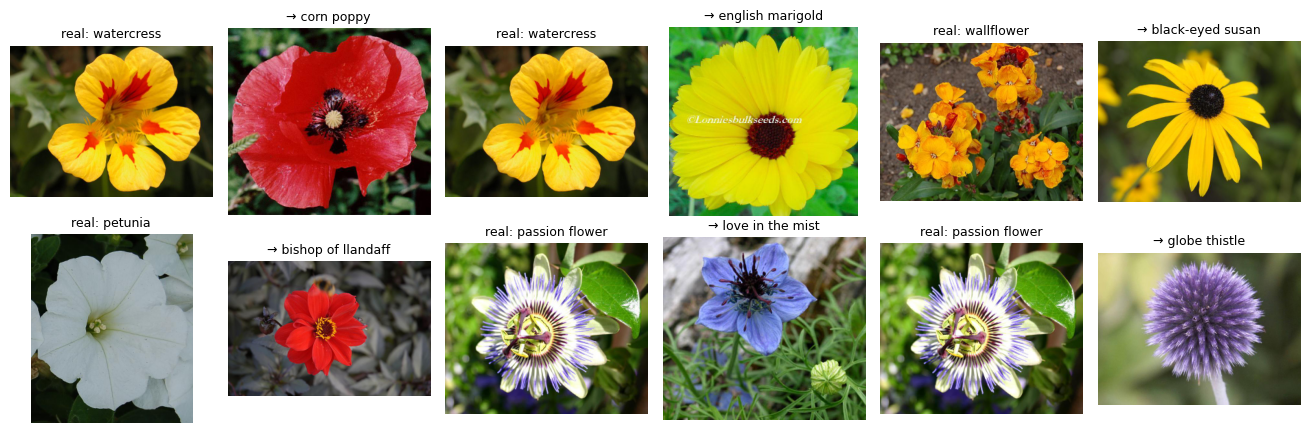

In [35]:
matriz = torch.zeros(102, 102)
matriz.index_put_((etiquetas[prueba], prediccion), torch.ones(len(prueba)), accumulate=True)
matriz.fill_diagonal_(0)
veces, posiciones = matriz.flatten().topk(6)
indices, titulos = [], []
for v, p in zip(veces.tolist(), posiciones.tolist()):
    real, predicha = p // 102, p % 102
    print(f"{NOMBRES[real]:18s} confundida con {NOMBRES[predicha]:24s} {int(v)} veces")
    indices += [torch.where(etiquetas == real)[0][0].item(), torch.where(etiquetas == predicha)[0][0].item()]
    titulos += [f"real: {NOMBRES[real]}", f"→ {NOMBRES[predicha]}"]
mostrar(indices, titulos, por_fila=6, alto=2.2)

Cada par de fotos es un ejemplo de la clase real y uno de la clase con la que se confunde. Varios pares comparten colores y tienen formas parecidas en una foto chica, como las petunias violetas y los penachos (*prince of wales feathers*), o los berros (*watercress*), florecitas blancas en grupo, con otras flores en racimo. Son las "clases muy parecidas" que la página del VGG advierte, más las que se parecen solo para nuestros descriptores.

## 15. Qué cambió desde 2008

Las características de este notebook están **diseñadas a mano**: alguien decidió que el tono, los bordes y su disposición son lo que importa. Una década después, las redes convolucionales (módulo 4) y los transformers aprenden esas características a partir de los datos.

Dos trabajos conocidos usan Flowers 102 para medir cuánto se transfiere lo que aprende una red entrenada con muchísimas imágenes:

- **Big Transfer (BiT)**, de Kolesnikov y otros (2020), preentrena una ResNet con JFT-300M, un conjunto de 300 millones de imágenes, y después la ajusta con la división oficial de entrenamiento de cada dataset ([sección 3.2](https://arxiv.org/abs/1912.11370)). En Flowers 102 llega a 99.63% (tabla 1). También la evalúa con solo unas pocas fotos por clase, de 1 a 100 (figura 1).
- **Vision Transformer (ViT)**, de Dosovitskiy y otros (2021), con el mismo preentrenamiento llega a entre 99.68% y 99.74% según el tamaño del modelo ([tabla 2](https://arxiv.org/abs/2010.11929)).

Esas cifras son exactitud sobre las fotos, no promediada por clase, así que no se comparan exactamente con las del artículo. Pero la distancia es enorme: de 72.8% a más de 99%.

¿Por qué se sigue usando la división de 2008, con solo 10 fotos por clase para entrenar (20 con la validación)? Justamente por eso. Con tan pocos ejemplos, ningún modelo puede aprender a ver flores desde cero; lo que se mide es cuánto sirve lo que el modelo ya sabe. Y las clases parecidas entre sí obligan a que ese conocimiento sea fino. Es una forma barata de medir algo difícil.

## 16. Resumen

- Oxford Flowers 102 se publicó con el artículo de Nilsback y Zisserman (2008). Su dificultad: clases muy parecidas entre sí, mucha variación dentro de cada clase, y solo 10 fotos por clase para entrenar en la división oficial.
- Los archivos confirman lo que dice la página del VGG (102 clases, de 40 a 258 fotos) y explican las diferencias con el artículo: las 103 clases originales se volvieron 102 al fusionar las dos petunias, y sus 20 fotos sobrantes pasaron a la prueba.
- El artículo mide la exactitud **promediada por clase**. Con una prueba desigual, esa cifra no premia apostar a las clases grandes.
- Las segmentaciones publicadas aíslan la flor; un 2.7% falla y marca toda la foto como fondo.
- El color en **HSV** resiste los cambios de iluminación: al oscurecer una foto, casi solo cambia el brillo.
- Las **palabras visuales** (k-means) convierten un conjunto de píxeles o descriptores en un histograma, y la distancia **χ²** compara histogramas.
- Un **kernel** convierte distancias en similitudes. Con un clasificador sobre kernels, el color logra 38.8% por clase; nuestros descriptores de forma, simplificados y de baja resolución, alrededor de 20%.
- **Combinar** los tres kernels lleva a 50.2%: cada característica aporta lo que las otras no ven. Es la tesis del artículo (55.1% → 72.8% con sus descriptores).
- Los ejemplos del artículo se cumplen: el color separa girasol de margarita, la forma separa ranúnculo de diente de león, y la boca de dragón, que existe en muchos colores, no se reconoce por el color.
- Recortar la flor ayuda a HOG, pero el color de la foto entera es mejor que el de la flor sola: el fondo es información, y también un atajo.
- Las redes preentrenadas con cientos de millones de imágenes superan el 99% en este dataset.

## Ejercicios

1. Cambia el número de palabras de color (`K_COLOR`) a 25, 50, 300 y 1.000, y elige el mejor en la **validación**, como hace el artículo (que buscó entre 100 y 5.000). ¿Cuánto cambia la exactitud en la prueba del mejor?
2. Implementa el cuarto descriptor del artículo: los gradientes locales calculados solo a lo largo del **borde** de la flor. Usa la máscara para encontrar los píxeles del contorno (por ejemplo, los que son flor y tienen un vecino que es fondo) y calcula descriptores centrados en ellos. ¿Mejora la combinación?
3. El artículo aprende pesos **para cada clase**. Implementa una versión: para cada clase, elige en la validación los pesos de su clasificador uno contra el resto entre algunas opciones. ¿Supera a los pesos iguales?
4. Con el vecino más cercano y el color, mide la exactitud por clase usando como referencia 1, 2, 5, 10 y 20 fotos por clase. Grafica la curva. ¿Cuántas fotos por clase harían falta para llegar al 50%, si sigue la tendencia?
5. La página del VGG publica las matrices de distancias χ² que usó el artículo (`distancematrices102.mat`, unos 2 GB, con `D_hsv`, `D_hog`, `D_siftint` y `D_siftbdy` según el README). Descárgalas y repite las secciones 10 y 11 con ellas. ¿Te acercas a la tabla 1? (Ojo: el artículo usó 103 clases.)
6. Toma las etiquetas de la copia [`nelorth/oxford-flowers`](https://huggingface.co/datasets/nelorth/oxford-flowers), donde las clases se llaman `'1'`, `'10'`, `'100'`, … Escribe la función que convierte su etiqueta en la etiqueta original y compruébala con la página de categorías. ¿Qué pasaría si mezclas resultados de las dos copias sin convertir?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **Visual Geometry Group, Oxford**, [*102 Category Flower Dataset*](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/). Sección *Overview*: "We have created a 102 category dataset, consisting of 102 flower categories. The flowers chosen to be flower commonly occuring in the United Kingdom. Each class consists of between 40 and 258 images." y "The images have large scale, pose and light variations. In addition, there are categories that have large variations within the category and several very similar categories." Sección *Downloads*: "Image segmentations", "&Chi 2 distances - As used in the ICVGIP 2008 publication."
  - [README.txt](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/README.txt): "We provide 4 distance matrices. D_hsv, D_hog, D_siftint, D_siftbdy. These are the chi^2 distance matrices used in the publication below." y, en *Datasplit*, "The results in the paper are produced on a 103 category database. The two categories labeled Petunia have since been merged since they are the same."
  - [Página de categorías](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/categories.html): la miniatura y el número de fotos de cada clase (por ejemplo, "petunia 258", "passion flower 251", "alpine sea holly 43").
- **M.-E. Nilsback y A. Zisserman** (2008), [*Automated flower classification over a large number of classes*](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/nilsback08.pdf), Indian Conference on Computer Vision, Graphics and Image Processing ([ficha](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/)):
  - Resumen: "we introduce a 103 class flower dataset", "the lo- cal shape/texture, the shape of the boundary, the overall spatial distribution of petals, and the colour", "large between class similarity and small within class similarity" y "from 55.1% for the best single feature to 72.8% for the combination of all features".
  - Sección 1: "flowers are non-rigid objects that can deform in many ways, and consequently there is also a large variation within classes"; "sometimes the colour, e.g. blue-bell vs sunflower, sometimes the shape, e.g. daffodil vs dandelion"; y la segmentación hace que "the background clutter has been removed".
  - Sección 2: el esquema iterativo de segmentación ("an initial flower segmentation is obtained using general (non-class specific) foreground and background colour distributions", "A generic flower shape model is then fitted", "The MRF segmentation is repeated using this new colour model").
  - Sección 3: "to discriminate a sunflower from a daisy, colour is a useful cue but shape would be quite poor. Conversely, to differentiate a buttercup from a dandelion, shape would be much more useful, but colour would not."
  - Sección 3.1: "The HSV space is chosen because it is less sensitive to variations in illumination and should be able to cope better with pictures of flowers taken in different weather conditions and at different time of the day. The HSV values for each pixel in an image are clustered using k-means"; "SIFT descriptors are computed at points on a regular grid", "Only the grey value is used (not colour), and the resulting SIFT descriptor is a 128 vector"; "the HOG is applied here over the entire flower region (and it is not made rotation invariant). In this manner it captures the more global spatial distribution of the flower, such as the overall arrangement of petals", "We find the smallest bounding box enclosing the foreground segmentation".
  - Sección 3.2: "χ²(x, y) is the symmetric Chi-squared distance between histograms x and y", "The parameter γf is set to 1/mean value of the χ² distances between the vectors xf over all the training images", "a set of parameters βf is learnt for each class as a one-vs-rest classifier".
  - Sección 4: "8189 images divided into 103 flower classes", "Each class consists of between 40 and 250 images", "Passion flower has the greatest number of images", "The images are rescaled so that the smallest dimension is 500 pixels", "The training set and validation set each consist of 10 images per class (totalling 1030 images each). The test set consist of the remaining 6129 images (minimum 20 per class)", "the final performance is the classification averaged over all classes (not over all images)".
  - Sección 4.1: "For colour the search is over the range 100 to 5000", "The optimum number of words is 1000 for the colour features, 8000 for the SIFT over the entire foreground region", "the classifiers are retrained using all the available training data (both the training and validation sets)".
  - Sección 5: "some classes like Snapdragon, are not well distinguished by colour, but for the orange Dahlia the colour weight is relatively strong. This is because the Snapdragon occurs in many different colours, whereas the orange dahlia only occurs in one colour."
  - Tabla 1: "HSV 43.0%", "SIFT internal 55.1%", "HOG 49.6%", "HSV + SIFT int + SIFT bd + HOG 72.8%".
  - Sección 6: "We report here instead the results of a first nearest neighbour classifier using χ² as the distance function."
- **Hugging Face**: [`dpdl-benchmark/oxford_flowers102`](https://huggingface.co/datasets/dpdl-benchmark/oxford_flowers102) (en su tarjeta: "'0': pink primrose", "'1': hard-leaved pocket orchid", …, y las divisiones "train … num_examples: 1020", "test … num_examples: 6149", "validation … num_examples: 1020"); [`nelorth/oxford-flowers`](https://huggingface.co/datasets/nelorth/oxford-flowers) ("'0': '1'", "'1': '10'", "'2': '100'", y "train … num_examples: 7169", "test … num_examples: 1020").

**Documentación**

- torchvision, [`Flowers102`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.Flowers102.html): "This class needs scipy to load target files from .mat format." y "Each class consists of between 40 and 258 images."
- Pillow, [`Image.draft`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.draft): "Configures the image file loader so it returns a version of the image that as closely as possible matches the given mode and size." y "It is currently implemented only for JPEG and MPO images."
- Pillow, [modos de imagen](https://pillow.readthedocs.io/en/stable/handbook/concepts.html#modes): "HSV (3x8-bit pixels, Hue, Saturation, Value color space) Hue’s range of 0-255 is a scaled version of 0 degrees <= Hue < 360 degrees".

**Artículos que no están en la lista del curso**

- A. Kolesnikov, L. Beyer, X. Zhai, J. Puigcerver, J. Yung, S. Gelly y N. Houlsby (2020), [*Big Transfer (BiT): General Visual Representation Learning*](https://arxiv.org/abs/1912.11370), ECCV. Sección 3.2: "We fine-tune BiT on the official training split and report results on the official test split if publicly available." Tabla 1: "Flowers 99.63 ± 0.03". Sección 1: "Oxford Flowers-102 [39] (including few-shot variants)"; figura 1: "BiT-L performs well even when transferred using only few images (1 to 100) per class."
- A. Dosovitskiy y otros (2021), [*An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*](https://arxiv.org/abs/2010.11929), ICLR. Tabla 2, fila "Oxford Flowers-102": "99.68 ± 0.02" (ViT-H/14, JFT), "99.74 ± 0.00" (ViT-L/16, JFT), "99.61 ± 0.02" (ViT-L/16, ImageNet-21k) y "99.63 ± 0.03" (BiT-L).

**Lo que no viene de una fuente** son los números de este notebook (conteos, tamaños, segmentaciones fallidas, exactitudes y confusiones): todos salen de las celdas de código. También son nuestros la deducción sobre dónde quedaron las fotos de la segunda petunia, la comprobación de HSV con una foto oscurecida, las versiones simplificadas de los descriptores, el uso de regresión ridge con kernel en lugar de una SVM, la comparación de la sección 12 y la lectura de las confusiones.